In [1]:
# NOTEBOOK CELL 1 — VERIFY THE GPU AND ENVIRONMENT

import os
import sys
import tensorflow as tf
import numpy as np
import pandas as pd

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

I0000 00:00:1791888771.752145     684 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791888772.588684     684 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791888776.922304     684 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python: 3.12.13 (main, May  6 2026, 18:46:41) [GCC 15.2.0]
Python executable: /home/aahana/ml-gpu/bin/python
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
NumPy: 2.5.2
Pandas: 3.0.5


In [2]:
# NOTEBOOK CELL 2 — IMPORT LIBRARIES AND SET RANDOM SEEDS

import re
import json
import html
import string
import random
import zipfile
import warnings
import subprocess
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from gensim.models import Word2Vec

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Embedding,
    SimpleRNN,
    Bidirectional,
    LSTM,
    GlobalMaxPooling1D,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = Path.home() / "FlipItNews"
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for folder in [DATA_DIR, MODEL_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("Project directory:", PROJECT_DIR)
print("GPU:", tf.config.list_physical_devices("GPU"))

ModuleNotFoundError: No module named 'nltk'

In [3]:
%pip install nltk gensim scikit-learn seaborn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 46.4 kB/s  0:00:34 eta 0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 958.7 kB/s  0:01:22m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.8/807.8 kB 2.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [gensim]2m3/4 [gensim]
Note: you may need to restart the kernel to use updated packages.


In [4]:
# NOTEBOOK CELL 2 — IMPORT LIBRARIES AND SET RANDOM SEEDS

import re
import json
import html
import string
import random
import zipfile
import warnings
import subprocess
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from gensim.models import Word2Vec

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Embedding,
    SimpleRNN,
    Bidirectional,
    LSTM,
    GlobalMaxPooling1D,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = Path.home() / "FlipItNews"
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for folder in [DATA_DIR, MODEL_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("Project directory:", PROJECT_DIR)
print("GPU:", tf.config.list_physical_devices("GPU"))

Project directory: /home/aahana/FlipItNews
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# NOTEBOOK CELL 3 — IDENTIFY AND EXTRACT THE DOWNLOADED DATASET

download_path = DATA_DIR / "dataset_download"

if not download_path.exists():
    raise FileNotFoundError(
        f"Dataset download not found: {download_path}. "
        "Download the Google Drive dataset from the WSL terminal first."
    )

print("Downloaded file size:", download_path.stat().st_size, "bytes")
print("Detected file signature:", download_path.read_bytes()[:100])

EXTRACT_DIR = DATA_DIR / "extracted"
EXTRACT_DIR.mkdir(exist_ok=True)

if zipfile.is_zipfile(download_path):
    with zipfile.ZipFile(download_path) as z:
        z.extractall(EXTRACT_DIR)
    print("ZIP archive extracted.")
else:
    print("Downloaded file is not a ZIP archive.")

for path in DATA_DIR.rglob("*"):
    if path.is_file():
        print(path.relative_to(DATA_DIR), path.stat().st_size, "bytes")

FileNotFoundError: Dataset download not found: /home/aahana/FlipItNews/data/dataset_download. Download the Google Drive dataset from the WSL terminal first.

In [7]:
# CELL 3 FIX — INSPECT THE DOWNLOADED FILE AND DETECT ITS FORMAT

from pathlib import Path
import pandas as pd
import csv

DATA_DIR = Path.home() / "FlipItNews" / "data"
csv_path = DATA_DIR / "flipitnews-data.csv"

print("File exists:", csv_path.exists())

if csv_path.exists():
    print("File size:", csv_path.stat().st_size, "bytes")

    with open(csv_path, "rb") as f:
        print("First bytes:", f.read(300))

    with open(csv_path, "r", encoding="utf-8-sig", errors="replace") as f:
        for i in range(10):
            line = f.readline()
            if not line:
                break
            print(f"Line {i + 1}: {line[:500]!r}")

    with open(csv_path, "r", encoding="utf-8-sig", errors="replace") as f:
        sample = f.read(20000)

    try:
        dialect = csv.Sniffer().sniff(sample, delimiters=",;\t|")
        print("\nDetected delimiter:", repr(dialect.delimiter))
        print("Detected quote character:", repr(dialect.quotechar))
    except csv.Error:
        print("\nDelimiter detection was inconclusive.")
else:
    print("File not found. Check the download cell.")

File exists: True
File size: 5080260 bytes
First bytes: b'category\tfilename\ttitle\tcontent\nbusiness\t001.txt\tAd sales boost Time Warner profit\t Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (\xc2\xa3600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from '
Line 1: 'category\tfilename\ttitle\tcontent\n'
Line 2: 'business\t001.txt\tAd sales boost Time Warner profit\t Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users'
Line 3: "business\t002.txt\tDollar gains on Greenspan speech\t The

In [8]:
# CELL 4 FIX — LOAD THE DATASET

import pandas as pd
from pathlib import Path

csv_path = Path.home() / "FlipItNews" / "data" / "flipitnews-data.csv"

try:
    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig",
        engine="python",
        sep=None,
        on_bad_lines="error"
    )
    print("Dataset loaded successfully.")

except Exception as e:
    print("Automatic parsing failed:", repr(e))
    print("Inspect the output of the previous cell before choosing a delimiter.")
    raise

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset loaded successfully.
Shape: (2225, 4)
Columns: ['category', 'filename', 'title', 'content']


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


In [9]:
# CELL 5 — INSPECT THE DATASET

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
display(df.nunique(dropna=True).to_frame("Unique Values"))

Dataset shape: (2225, 4)

Column names:
['category', 'filename', 'title', 'content']

Data types:


,Data Type
category,str
filename,str
title,str
content,str



First 5 rows:


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...



Missing values:


,Missing Values
category,0
filename,0
title,0
content,0



Duplicate rows: 0

Unique values per column:


,Unique Values
category,5
filename,511
title,2096
content,2092


In [10]:
# CELL 6 — IDENTIFY TEXT AND CATEGORY COLUMNS

import re

normalized_columns = {
    re.sub(r"[^a-z0-9]+", "_", str(col).strip().lower()).strip("_"): col
    for col in df.columns
}

category_candidates = [
    "category", "categories", "news_category", "label",
    "class", "topic", "target", "type"
]

text_candidates = [
    "text", "article", "content", "news", "article_text",
    "description", "body", "headline", "title"
]

CATEGORY_COL = next(
    (normalized_columns[c] for c in category_candidates if c in normalized_columns),
    None
)

TEXT_COL = next(
    (normalized_columns[c] for c in text_candidates if c in normalized_columns),
    None
)

print("Detected category column:", CATEGORY_COL)
print("Detected text column:", TEXT_COL)

if CATEGORY_COL is None or TEXT_COL is None:
    print("\nAvailable columns:", df.columns.tolist())
    print("Set CATEGORY_COL and TEXT_COL manually based on the displayed columns.")
else:
    display(df[[CATEGORY_COL, TEXT_COL]].head())

Detected category column: category
Detected text column: content


,category,content
0,business,Quarterly profits at US media giant TimeWarne...
1,business,The dollar has hit its highest level against ...
2,business,The owners of embattled Russian oil giant Yuk...
3,business,British Airways has blamed high fuel prices f...
4,business,Shares in UK drinks and food firm Allied Dome...


Number of categories: 5


,Article Count
category,
sport,511
business,510
politics,417
tech,401
entertainment,386


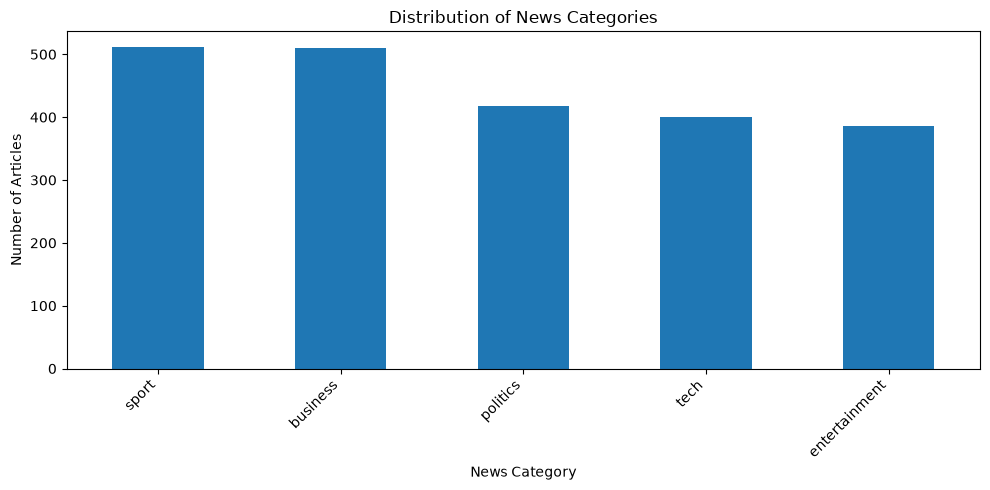

In [11]:
# CELL 7 — CHECK CATEGORY DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns

if CATEGORY_COL is None:
    raise ValueError("Set CATEGORY_COL manually in Cell 6.")

print("Number of categories:", df[CATEGORY_COL].nunique())
display(df[CATEGORY_COL].value_counts(dropna=False).to_frame("Article Count"))

plt.figure(figsize=(10, 5))
df[CATEGORY_COL].value_counts().plot(kind="bar")
plt.title("Distribution of News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

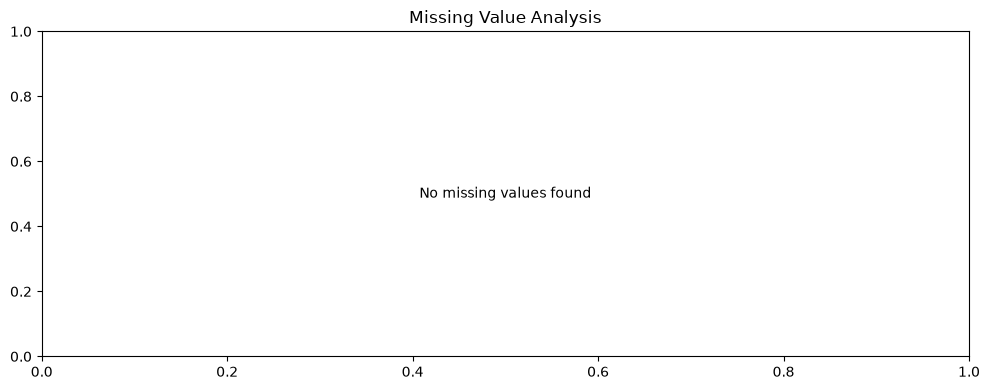

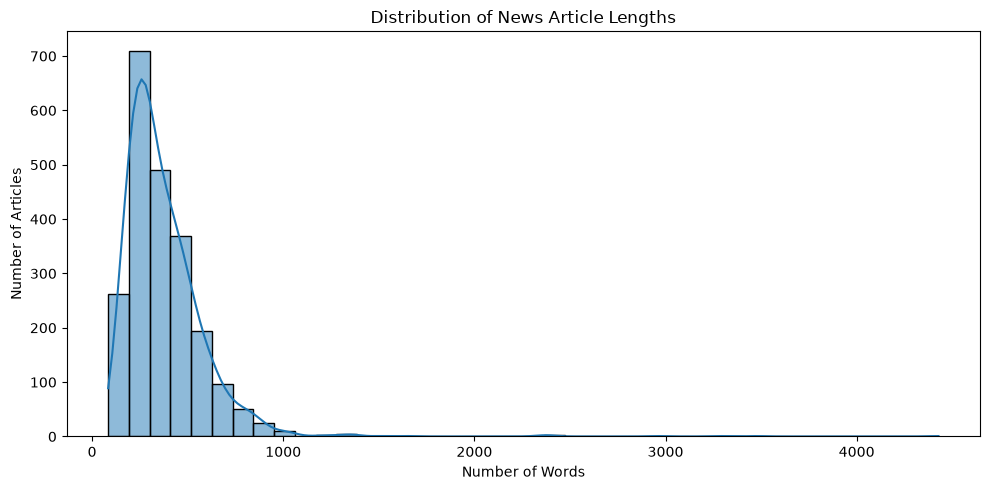

count    2225.000000
mean      378.835955
std       238.220755
min        84.000000
25%       240.000000
50%       326.000000
75%       466.000000
max      4428.000000
Name: content, dtype: float64


In [12]:
# CELL 8 — VISUALIZE MISSING VALUES AND ARTICLE LENGTHS

if TEXT_COL is None:
    raise ValueError("Set TEXT_COL manually in Cell 6.")

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 4))
if len(missing):
    missing.plot(kind="bar")
    plt.ylabel("Missing Values")
    plt.title("Missing Values by Column")
else:
    plt.text(0.5, 0.5, "No missing values found", ha="center", va="center")
    plt.title("Missing Value Analysis")

plt.tight_layout()
plt.show()

article_lengths = df[TEXT_COL].fillna("").astype(str).str.split().str.len()

plt.figure(figsize=(10, 5))
sns.histplot(article_lengths, bins=40, kde=True)
plt.title("Distribution of News Article Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

print(article_lengths.describe())

In [13]:
# CELL 9 — CLEAN THE DATASET

df = df[[CATEGORY_COL, TEXT_COL]].copy()

df[CATEGORY_COL] = df[CATEGORY_COL].astype("string").str.strip()
df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)

df = df.dropna(subset=[CATEGORY_COL])

df = df[
    (df[CATEGORY_COL] != "") &
    (df[TEXT_COL].str.strip() != "")
].copy()

df = df.drop_duplicates(subset=[CATEGORY_COL, TEXT_COL])
df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nCategory counts:")
display(df[CATEGORY_COL].value_counts().to_frame("Article Count"))

Dataset shape after cleaning: (2092, 2)

Missing values:


,Missing Values
category,0
content,0



Category counts:


,Article Count
category,
business,500
sport,494
politics,395
entertainment,366
tech,337


In [14]:
# CELL 10 — PREPROCESS TEXT

import html
import string
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = word_tokenize(text)

    tokens = [
        token for token in tokens
        if token not in stop_words and len(token) > 1
    ]

    return tokens

df["tokens"] = df[TEXT_COL].apply(preprocess_text)
df["clean_text"] = df["tokens"].apply(lambda tokens: " ".join(tokens))

df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)

display(df[[CATEGORY_COL, TEXT_COL, "clean_text"]].head())
print("Records after preprocessing:", len(df))

,category,content,clean_text
0,business,Quarterly profits at US media giant TimeWarne...,quarterly profits us media giant timewarner ju...
1,business,The dollar has hit its highest level against ...,dollar hit highest level euro almost three mon...
2,business,The owners of embattled Russian oil giant Yuk...,owners embattled russian oil giant yukos ask b...
3,business,British Airways has blamed high fuel prices f...,british airways blamed high fuel prices drop p...
4,business,Shares in UK drinks and food firm Allied Dome...,shares uk drinks food firm allied domecq risen...


Records after preprocessing: 2092


In [15]:
# CELL 11 — ENCODE LABELS AND SPLIT THE DATA

import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

SEED = 42

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df[CATEGORY_COL])

class_names = label_encoder.classes_.tolist()
num_classes = len(class_names)

X_text = df["clean_text"].to_numpy()
X_tokens = df["tokens"].tolist()
y = df["label"].to_numpy()

X_train_text, X_test_text, X_train_tokens, X_test_tokens, y_train, y_test = train_test_split(
    X_text,
    X_tokens,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train_text, X_val_text, X_train_tokens, X_val_tokens, y_train, y_val = train_test_split(
    X_train_text,
    X_train_tokens,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))
print("Testing samples:", len(X_test_text))
print("Categories:", class_names)

Training samples: 1422
Validation samples: 251
Testing samples: 419
Categories: ['business', 'entertainment', 'politics', 'sport', 'tech']


In [16]:
# CELL 12 — EXTRACT BAG OF WORDS FEATURES

from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_bow = bow_vectorizer.fit_transform(X_train_text)
X_val_bow = bow_vectorizer.transform(X_val_text)
X_test_bow = bow_vectorizer.transform(X_test_text)

print("BoW training shape:", X_train_bow.shape)
print("BoW validation shape:", X_val_bow.shape)
print("BoW test shape:", X_test_bow.shape)

BoW training shape: (1422, 10000)
BoW validation shape: (251, 10000)
BoW test shape: (419, 10000)


In [17]:
# CELL 13 — EXTRACT TF-IDF FEATURES

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_val_tfidf = tfidf_vectorizer.transform(X_val_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF validation shape:", X_val_tfidf.shape)
print("TF-IDF test shape:", X_test_tfidf.shape)

TF-IDF training shape: (1422, 10000)
TF-IDF validation shape: (251, 10000)
TF-IDF test shape: (419, 10000)


In [18]:
# CELL 14 — WORD2VEC FEATURE EXTRACTION

import os
import numpy as np
from gensim.models import Word2Vec

EMBEDDING_DIM = 100

word2vec_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=2,
    workers=max(1, (os.cpu_count() or 2) - 1),
    sg=1,
    epochs=10,
    seed=42
)

def average_word2vec(tokens, model, vector_size=100):
    vectors = [
        model.wv[token]
        for token in tokens
        if token in model.wv
    ]

    if not vectors:
        return np.zeros(vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0).astype(np.float32)

X_train_w2v = np.vstack([
    average_word2vec(tokens, word2vec_model)
    for tokens in X_train_tokens
])

X_val_w2v = np.vstack([
    average_word2vec(tokens, word2vec_model)
    for tokens in X_val_tokens
])

X_test_w2v = np.vstack([
    average_word2vec(tokens, word2vec_model)
    for tokens in X_test_tokens
])

print("Word2Vec training:", X_train_w2v.shape)
print("Word2Vec validation:", X_val_w2v.shape)
print("Word2Vec testing:", X_test_w2v.shape)

Word2Vec training: (1422, 100)
Word2Vec validation: (251, 100)
Word2Vec testing: (419, 100)


In [20]:
# CELL 15 — TRAIN A NEURAL NETWORK USING WORD2VEC

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

nn_model = Sequential([
    Input(shape=(EMBEDDING_DIM,)),
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

nn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

nn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,421 (236.02 KB)

 Trainable params: 59,909 (234.02 KB)

 Non-trainable params: 512 (2.00 KB)

In [22]:
# CELL 16 — FIT THE NEURAL NETWORK

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

nn_history = nn_model.fit(
    X_train_w2v,
    y_train,
    validation_data=(X_val_w2v, y_val),
    epochs=15,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

nn_model.save(str(MODEL_DIR / "flipitnews_nn.keras"))

Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9887 - loss: 0.0440 - val_accuracy: 0.9562 - val_loss: 0.1186 - learning_rate: 5.0000e-04
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9895 - loss: 0.0348 - val_accuracy: 0.9602 - val_loss: 0.1169 - learning_rate: 5.0000e-04
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9866 - loss: 0.0419 - val_accuracy: 0.9522 - val_loss: 0.1165 - learning_rate: 5.0000e-04
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9859 - loss: 0.0398 - val_accuracy: 0.9641 - val_loss: 0.1201 - learning_rate: 5.0000e-04
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9831 - loss: 0.0388 - val_accuracy: 0.9641 - val_loss: 0.1278 - learning_rate: 5.0000e-04
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9937 - loss: 0.0281 - val_accuracy: 0.9602 - val_loss: 0.1281 - learning_rate: 2.5000e-04


In [23]:
# CELL 17 — PREPARE TEXT SEQUENCES FOR THE RNN

import joblib
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 30000
MAX_SEQUENCE_LENGTH = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_train_text),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

X_val_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_val_text),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

X_test_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_test_text),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

VOCAB_SIZE = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Vocabulary size:", VOCAB_SIZE)
print("Training sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Testing sequences:", X_test_seq.shape)

joblib.dump(tokenizer, MODEL_DIR / "rnn_tokenizer.joblib")

Vocabulary size: 26041
Training sequences: (1422, 300)
Validation sequences: (251, 300)
Testing sequences: (419, 300)


['/home/aahana/FlipItNews/models/rnn_tokenizer.joblib']

In [24]:
# CELL 18 — BUILD THE RECURRENT NEURAL NETWORK

from tensorflow.keras.layers import Embedding, Bidirectional, LSTM

rnn_model = Sequential([
    Input(shape=(MAX_SEQUENCE_LENGTH,)),
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True
    ),
    Bidirectional(LSTM(64)),
    Dropout(0.4),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     3,333,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,440,645 (13.13 MB)

 Trainable params: 3,440,645 (13.13 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# CELL 19 — TRAIN THE RNN ON YOUR GPU

rnn_history = rnn_model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=12,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

rnn_model.save(str(MODEL_DIR / "flipitnews_rnn.keras"))
joblib.dump(label_encoder, MODEL_DIR / "label_encoder.joblib")

print("RNN training completed and model saved.")

Epoch 1/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 15s 164ms/step - accuracy: 0.3073 - loss: 1.5678 - val_accuracy: 0.4582 - val_loss: 1.2354 - learning_rate: 0.0010
Epoch 2/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 146ms/step - accuracy: 0.7314 - loss: 0.7940 - val_accuracy: 0.8765 - val_loss: 0.4795 - learning_rate: 0.0010
Epoch 3/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 133ms/step - accuracy: 0.9459 - loss: 0.2515 - val_accuracy: 0.9442 - val_loss: 0.2345 - learning_rate: 0.0010
Epoch 4/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 148ms/step - accuracy: 0.9669 - loss: 0.1436 - val_accuracy: 0.9363 - val_loss: 0.2823 - learning_rate: 0.0010
Epoch 5/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.9916 - loss: 0.0670 - val_accuracy: 0.9482 - val_loss: 0.2036 - learning_rate: 0.0010
Epoch 6/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - accuracy: 0.9944 - loss: 0.0283 - val_accuracy: 0.9363 - val_loss: 0.1901 - learning_rate: 0.0010
Epoch 7/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.9993 - loss: 0.0085 -

In [26]:
# CELL 20 — EVALUATE BOTH MODELS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

nn_pred = np.argmax(nn_model.predict(X_test_w2v, verbose=0), axis=1)
rnn_pred = np.argmax(rnn_model.predict(X_test_seq, verbose=0), axis=1)

results.append(evaluate_model("Word2Vec + Neural Network", y_test, nn_pred))
results.append(evaluate_model("Embedding + BiLSTM RNN", y_test, rnn_pred))

results_df = pd.DataFrame(results)
display(results_df.round(4))

print("\nRNN Classification Report:\n")
print(classification_report(
    y_test,
    rnn_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

,Model,Accuracy,Precision,Recall,F1-Score
0,Word2Vec + Neural Network,0.9690,0.9692,0.9690,0.9690
1,Embedding + BiLSTM RNN,0.9475,0.9483,0.9475,0.9476



RNN Classification Report:

               precision    recall  f1-score   support

     business       0.98      0.93      0.95       100
entertainment       0.91      0.96      0.93        73
     politics       0.95      0.94      0.94        79
        sport       0.96      0.97      0.96        99
         tech       0.93      0.94      0.93        68

     accuracy                           0.95       419
    macro avg       0.94      0.95      0.95       419
 weighted avg       0.95      0.95      0.95       419



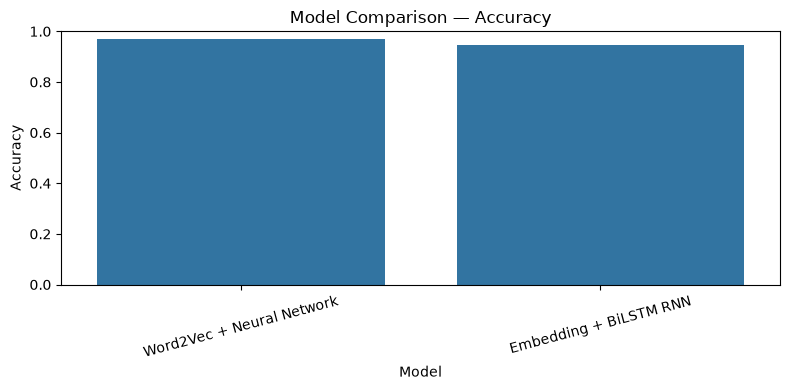

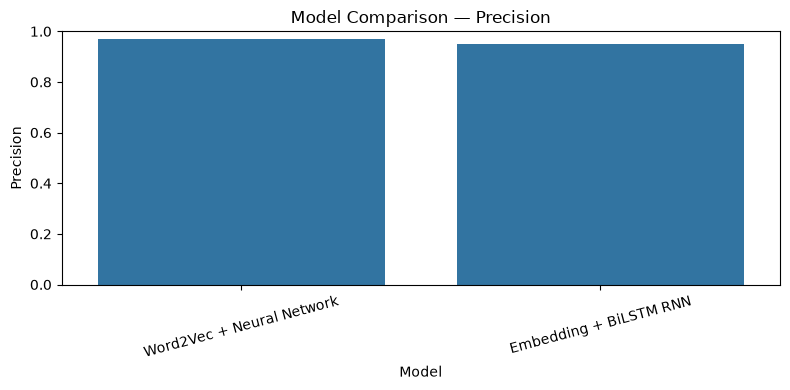

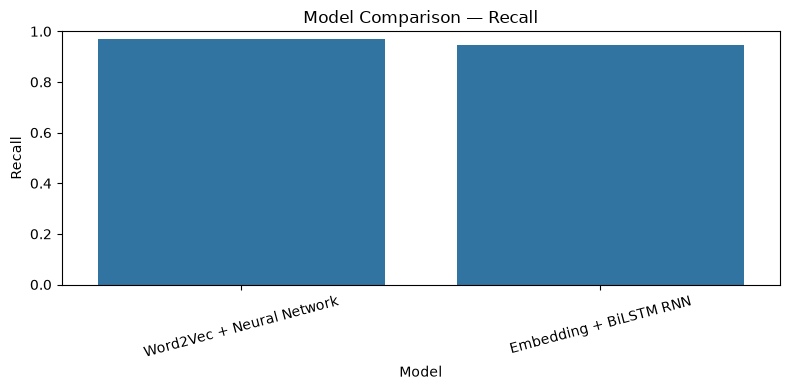

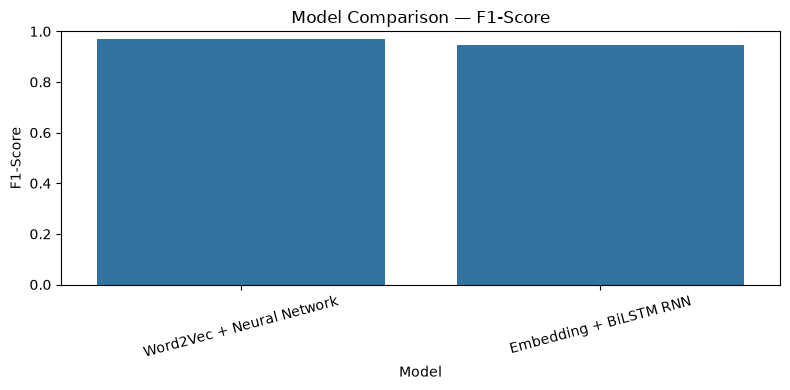

In [27]:
# CELL 21 — COMPARE THE MODEL PERFORMANCE

import matplotlib.pyplot as plt
import seaborn as sns

for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    plt.figure(figsize=(8, 4))
    sns.barplot(data=results_df, x="Model", y=metric)
    plt.ylim(0, 1)
    plt.title(f"Model Comparison — {metric}")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

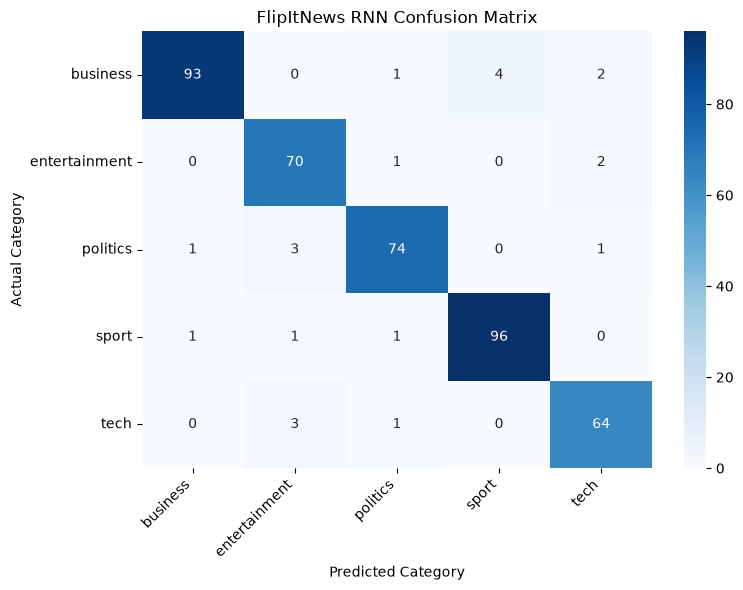

In [28]:
# CELL 22 — CONFUSION MATRIX FOR THE RNN

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rnn_pred, labels=np.arange(num_classes))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True if num_classes <= 10 else False,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("FlipItNews RNN Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rnn_confusion_matrix.png", dpi=150)
plt.show()

In [29]:
print("Word2Vec model:", "word2vec_model" in globals())
print("Neural network:", "nn_model" in globals())
print("RNN model:", "rnn_model" in globals())
print("TF-IDF features:", X_train_tfidf.shape)
print("BoW features:", X_train_bow.shape)
print("Number of classes:", num_classes)
print("Classes:", class_names)

Word2Vec model: True
Neural network: True
RNN model: True
TF-IDF features: (1422, 10000)
BoW features: (1422, 10000)
Number of classes: 5
Classes: ['business', 'entertainment', 'politics', 'sport', 'tech']


In [30]:
import os
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

results = []
trained_models = {}

def evaluate_model(name, model, X, y_true):
    y_pred = model.predict(X)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"\n{name}")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0
    ))

    return y_pred

In [31]:
from joblib import dump

traditional_models = {
    "BoW - Logistic Regression": (
        LogisticRegression(max_iter=1500, class_weight="balanced"),
        X_train_bow,
        X_val_bow
    ),
    "TF-IDF - Logistic Regression": (
        LogisticRegression(max_iter=1500, class_weight="balanced"),
        X_train_tfidf,
        X_val_tfidf
    ),
    "TF-IDF - Linear SVM": (
        LinearSVC(class_weight="balanced"),
        X_train_tfidf,
        X_val_tfidf
    ),
    "BoW - Naive Bayes": (
        MultinomialNB(),
        X_train_bow,
        X_val_bow
    )
}

for name, (model, X_train, X_val) in traditional_models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model
    evaluate_model(name, model, X_val, y_val)

dump(trained_models, "models/traditional_models.joblib")


Training BoW - Logistic Regression...

BoW - Logistic Regression
               precision    recall  f1-score   support

     business       0.95      0.95      0.95        60
entertainment       0.91      0.95      0.93        44
     politics       0.98      0.96      0.97        48
        sport       1.00      1.00      1.00        59
         tech       0.97      0.95      0.96        40

     accuracy                           0.96       251
    macro avg       0.96      0.96      0.96       251
 weighted avg       0.96      0.96      0.96       251


Training TF-IDF - Logistic Regression...

TF-IDF - Logistic Regression
               precision    recall  f1-score   support

     business       0.97      0.98      0.98        60
entertainment       0.98      0.95      0.97        44
     politics       0.96      1.00      0.98        48
        sport       1.00      1.00      1.00        59
         tech       0.97      0.93      0.95        40

     accuracy                   

['models/traditional_models.joblib']

In [33]:
X_val_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_val_text),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

In [35]:
nn_val_probabilities = nn_model.predict(X_val_w2v, verbose=0)
nn_val_predictions = np.argmax(nn_val_probabilities, axis=1)
evaluate_model("Word2Vec Neural Network", nn_model, X_val_w2v, y_val)

rnn_val_probabilities = rnn_model.predict(X_val_pad, verbose=0)
rnn_val_predictions = np.argmax(rnn_val_probabilities, axis=1)
evaluate_model("BiLSTM RNN", rnn_model, X_val_pad, y_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


ValueError: Classification metrics can't handle a mix of multiclass and continuous-multioutput targets

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np

def evaluate_model(name, model, X, y_true):
    predictions = model.predict(X, verbose=0) if hasattr(model, "layers") else model.predict(X)

    # Convert neural-network probabilities into class labels
    if isinstance(predictions, np.ndarray) and predictions.ndim == 2:
        if predictions.shape[1] > 1:
            y_pred = np.argmax(predictions, axis=1)
        else:
            y_pred = (predictions.ravel() >= 0.5).astype(int)
    else:
        y_pred = predictions

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"\n{name}")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0
    ))

    return y_pred

In [37]:
nn_val_predictions = evaluate_model(
    "Word2Vec Neural Network",
    nn_model,
    X_val_w2v,
    y_val
)

rnn_val_predictions = evaluate_model(
    "BiLSTM RNN",
    rnn_model,
    X_val_pad,
    y_val
)


Word2Vec Neural Network
               precision    recall  f1-score   support

     business       0.95      0.95      0.95        60
entertainment       0.93      0.93      0.93        44
     politics       0.96      0.94      0.95        48
        sport       1.00      1.00      1.00        59
         tech       0.90      0.93      0.91        40

     accuracy                           0.95       251
    macro avg       0.95      0.95      0.95       251
 weighted avg       0.95      0.95      0.95       251


BiLSTM RNN
               precision    recall  f1-score   support

     business       0.98      0.93      0.96        60
entertainment       0.95      0.95      0.95        44
     politics       1.00      0.94      0.97        48
        sport       0.95      1.00      0.98        59
         tech       0.88      0.95      0.92        40

     accuracy                           0.96       251
    macro avg       0.95      0.96      0.95       251
 weighted avg       0.9

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("outputs", exist_ok=True)

results_df = pd.DataFrame(results)

# Remove duplicate model entries if any cells were rerun
results_df = results_df.drop_duplicates(subset=["Model"], keep="last")

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

results_df.to_csv("outputs/model_comparison.csv", index=False)

print("Model comparison saved successfully.")

,Model,Accuracy,Precision,Recall,F1 Score
0,BoW - Naive Bayes,0.9761,0.9767,0.9761,0.9761
1,TF-IDF - Logistic Regression,0.9761,0.9762,0.9761,0.9760
2,TF-IDF - Linear SVM,0.9721,0.9722,0.9721,0.9719
3,BoW - Logistic Regression,0.9641,0.9646,0.9641,0.9643
4,BiLSTM RNN,0.9562,0.9579,0.9562,0.9564
5,Word2Vec Neural Network,0.9522,0.9524,0.9522,0.9523


Model comparison saved successfully.


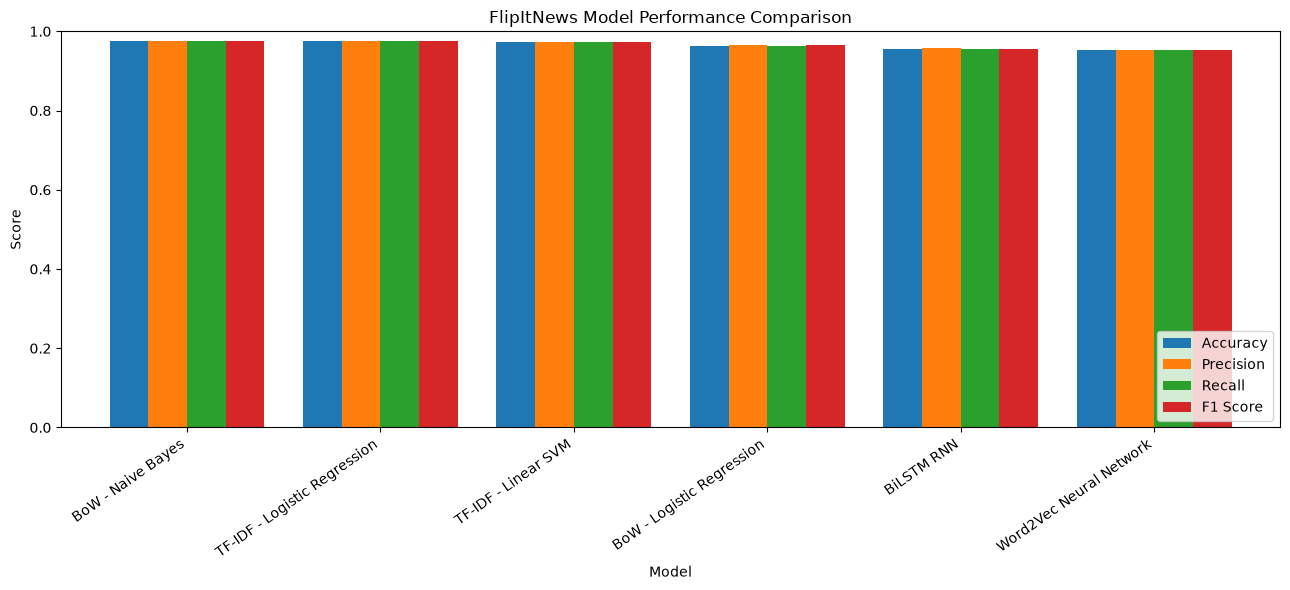

In [39]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

ax = results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("FlipItNews Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("outputs/model_performance_comparison.png", dpi=300)
plt.show()

In [40]:
from sklearn.metrics import accuracy_score, classification_report, f1_score
import numpy as np

best_model_name = results_df.iloc[0]["Model"]
print("Best model based on validation F1 score:", best_model_name)

if best_model_name in trained_models:
    best_model = trained_models[best_model_name]

    if "BoW" in best_model_name:
        X_test_best = X_test_bow
    else:
        X_test_best = X_test_tfidf

    y_test_predictions = best_model.predict(X_test_best)

elif best_model_name == "Word2Vec Neural Network":
    y_test_predictions = np.argmax(
        nn_model.predict(X_test_w2v, verbose=0), axis=1
    )

elif best_model_name == "BiLSTM RNN":
    y_test_predictions = np.argmax(
        rnn_model.predict(X_test_pad, verbose=0), axis=1
    )

print("\nFinal Test Classification Report")
print(classification_report(
    y_test,
    y_test_predictions,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

print("Test Accuracy:", round(accuracy_score(y_test, y_test_predictions), 4))
print("Test Weighted F1:", round(
    f1_score(y_test, y_test_predictions, average="weighted", zero_division=0), 4
))

Best model based on validation F1 score: BoW - Naive Bayes

Final Test Classification Report
               precision    recall  f1-score   support

     business       0.99      0.94      0.96       100
entertainment       0.99      0.95      0.97        73
     politics       0.94      0.97      0.96        79
        sport       1.00      0.99      0.99        99
         tech       0.91      0.99      0.94        68

     accuracy                           0.97       419
    macro avg       0.96      0.97      0.96       419
 weighted avg       0.97      0.97      0.97       419

Test Accuracy: 0.9666
Test Weighted F1: 0.9668


In [41]:
import json
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

if best_model_name in trained_models:
    joblib.dump(best_model, "models/best_traditional_model.joblib")
    joblib.dump(
        vectorizer_bow if "BoW" in best_model_name else vectorizer_tfidf,
        "models/best_vectorizer.joblib"
    )

elif best_model_name == "Word2Vec Neural Network":
    nn_model.save("models/best_model.keras")
    word2vec_model.save("models/word2vec.model")

else:
    rnn_model.save("models/best_model.keras")
    joblib.dump(tokenizer, "models/rnn_tokenizer.joblib")

joblib.dump(label_encoder, "models/label_encoder.joblib")

with open("models/config.json", "w") as f:
    json.dump({
        "best_model_name": best_model_name,
        "class_names": [str(c) for c in class_names],
        "num_classes": int(num_classes)
    }, f, indent=4)

print("Best model and configuration saved.")

NameError: name 'vectorizer_bow' is not defined

In [42]:
print("Vectorizer-related variables:")

for name, obj in globals().copy().items():
    if "vector" in name.lower() and obj is not None:
        print(name, ":", type(obj).__name__)

Vectorizer-related variables:
CountVectorizer : type
TfidfVectorizer : type
bow_vectorizer : CountVectorizer
tfidf_vectorizer : TfidfVectorizer


In [43]:
import os
import json
import joblib

os.makedirs("models", exist_ok=True)

if best_model_name in trained_models:
    joblib.dump(best_model, "models/best_traditional_model.joblib")

    # Automatically find the matching fitted vectorizer
    vectorizer_candidates = {
        name: obj
        for name, obj in globals().copy().items()
        if hasattr(obj, "vocabulary_") and hasattr(obj, "transform")
    }

    if "BoW" in best_model_name:
        candidates = [
            (name, obj) for name, obj in vectorizer_candidates.items()
            if "count" in name.lower() or "bow" in name.lower()
        ]
    else:
        candidates = [
            (name, obj) for name, obj in vectorizer_candidates.items()
            if "tfidf" in name.lower() or "tf_idf" in name.lower()
        ]

    if candidates:
        vectorizer_name, best_vectorizer = candidates[0]
        joblib.dump(best_vectorizer, "models/best_vectorizer.joblib")
        print("Saved vectorizer:", vectorizer_name)
    else:
        print("No matching fitted vectorizer found. Run Cell 1 and share its output.")

elif best_model_name == "Word2Vec Neural Network":
    nn_model.save("models/best_model.keras")
    word2vec_model.save("models/word2vec.model")

elif best_model_name == "BiLSTM RNN":
    rnn_model.save("models/best_model.keras")
    joblib.dump(tokenizer, "models/rnn_tokenizer.joblib")

joblib.dump(label_encoder, "models/label_encoder.joblib")

with open("models/config.json", "w") as f:
    json.dump({
        "best_model_name": best_model_name,
        "class_names": [str(c) for c in class_names],
        "num_classes": int(num_classes)
    }, f, indent=4)

print("Model-saving step completed.")

Saved vectorizer: bow_vectorizer
Model-saving step completed.


In [44]:
import os
import json
import joblib
import numpy as np

os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# Save label encoder and Word2Vec model
joblib.dump(label_encoder, "models/label_encoder.joblib")
word2vec_model.save("models/word2vec.model")
joblib.dump(tokenizer, "models/rnn_tokenizer.joblib")

# Save class names and preprocessing configuration
config = {
    "best_model_name": str(best_model_name),
    "class_names": [str(c) for c in class_names],
    "num_classes": int(num_classes),
    "max_sequence_length": int(MAX_SEQUENCE_LENGTH),
    "max_words": int(MAX_WORDS),
    "embedding_dim": int(EMBEDDING_DIM)
}

with open("models/config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Configuration and supporting files saved.")

Configuration and supporting files saved.


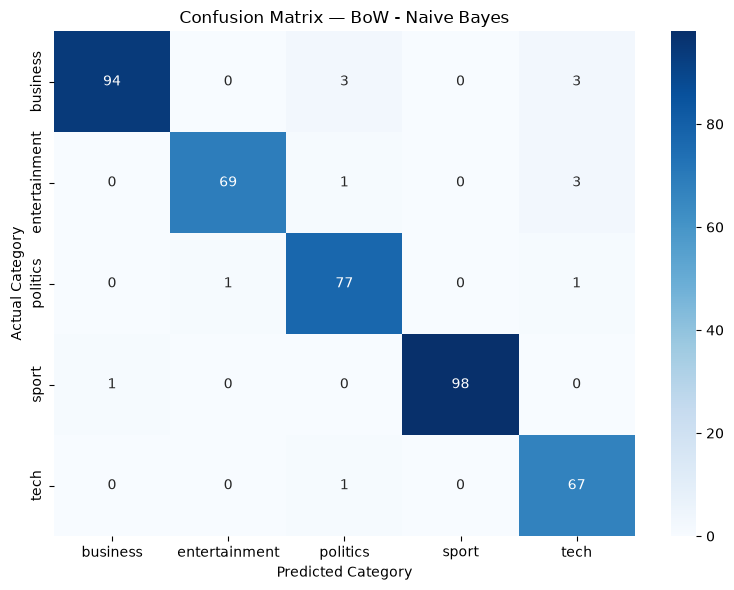

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_test_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()

plt.savefig("outputs/confusion_matrix.png", dpi=300)
plt.show()

In [46]:
from pathlib import Path

for folder in ["models", "outputs"]:
    print(f"\n{folder}/")
    for path in sorted(Path(folder).glob("*")):
        if path.is_file():
            print(f"  {path.name} — {path.stat().st_size / 1024:.1f} KB")


models/
  best_traditional_model.joblib — 782.1 KB
  best_vectorizer.joblib — 296.1 KB
  config.json — 0.3 KB
  label_encoder.joblib — 0.5 KB
  rnn_tokenizer.joblib — 1030.0 KB
  traditional_models.joblib — 1955.5 KB
  word2vec.model — 12616.9 KB

outputs/
  confusion_matrix.png — 125.3 KB
  model_comparison.csv — 0.6 KB
  model_performance_comparison.png — 190.1 KB


In [47]:
import os
from pathlib import Path

print("Current working directory:", os.getcwd())

for folder in ["data", "models", "outputs"]:
    path = Path(folder)
    print(f"\n--- {folder}/ ---")

    if path.exists():
        files = list(path.iterdir())
        if files:
            for file in sorted(files):
                if file.is_file():
                    print(f"  {file.name} ({file.stat().st_size / 1024:.1f} KB)")
                else:
                    print(f"  {file.name}/")
        else:
            print("  Folder is empty")
    else:
        print("  Folder not found")

Current working directory: /home/aahana/24CD3002_AI_ML_Application_Assignments/Assignment-9

--- data/ ---
  Folder not found

--- models/ ---
  best_traditional_model.joblib (782.1 KB)
  best_vectorizer.joblib (296.1 KB)
  config.json (0.3 KB)
  label_encoder.joblib (0.5 KB)
  rnn_tokenizer.joblib (1030.0 KB)
  traditional_models.joblib (1955.5 KB)
  word2vec.model (12616.9 KB)

--- outputs/ ---
  confusion_matrix.png (125.3 KB)
  model_comparison.csv (0.6 KB)
  model_performance_comparison.png (190.1 KB)


In [48]:
print("Dataset loaded:", "df" in globals())
if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 5 rows:")
    display(df.head())

print("\nTrain/validation/test split:")
for name in ["X_train_text", "X_val_text", "X_test_text",
             "y_train", "y_val", "y_test"]:
    if name in globals():
        print(f"{name}: {len(globals()[name])}")
    else:
        print(f"{name}: MISSING")

print("\nNumber of categories:", num_classes if "num_classes" in globals() else "MISSING")
print("Category names:", class_names if "class_names" in globals() else "MISSING")

Dataset loaded: True
Dataset shape: (2092, 5)
Columns: ['category', 'content', 'tokens', 'clean_text', 'label']

First 5 rows:


,category,content,tokens,clean_text,label
0,business,Quarterly profits at US media giant TimeWarne...,"[quarterly, profits, us, media, giant, timewar...",quarterly profits us media giant timewarner ju...,0
1,business,The dollar has hit its highest level against ...,"[dollar, hit, highest, level, euro, almost, th...",dollar hit highest level euro almost three mon...,0
2,business,The owners of embattled Russian oil giant Yuk...,"[owners, embattled, russian, oil, giant, yukos...",owners embattled russian oil giant yukos ask b...,0
3,business,British Airways has blamed high fuel prices f...,"[british, airways, blamed, high, fuel, prices,...",british airways blamed high fuel prices drop p...,0
4,business,Shares in UK drinks and food firm Allied Dome...,"[shares, uk, drinks, food, firm, allied, domec...",shares uk drinks food firm allied domecq risen...,0



Train/validation/test split:
X_train_text: 1422
X_val_text: 251
X_test_text: 419
y_train: 1422
y_val: 251
y_test: 419

Number of categories: 5
Category names: ['business', 'entertainment', 'politics', 'sport', 'tech']


In [49]:
feature_names = [
    "X_train_bow", "X_val_bow", "X_test_bow",
    "X_train_tfidf", "X_val_tfidf", "X_test_tfidf",
    "X_train_w2v", "X_val_w2v", "X_test_w2v",
    "X_train_pad", "X_val_pad", "X_test_pad"
]

for name in feature_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {getattr(obj, 'shape', 'exists; shape unavailable')}")
    else:
        print(f"{name}: MISSING")

print("\nSupporting objects:")
for name in ["bow_vectorizer", "word2vec_model", "tokenizer", "label_encoder"]:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")

X_train_bow: (1422, 10000)
X_val_bow: (251, 10000)
X_test_bow: (419, 10000)
X_train_tfidf: (1422, 10000)
X_val_tfidf: (251, 10000)
X_test_tfidf: (419, 10000)
X_train_w2v: (1422, 100)
X_val_w2v: (251, 100)
X_test_w2v: (419, 100)
X_train_pad: MISSING
X_val_pad: (251, 300)
X_test_pad: MISSING

Supporting objects:
bow_vectorizer: Available
word2vec_model: Available
tokenizer: Available
label_encoder: Available


In [50]:
for name in ["nn_model", "rnn_model", "trained_models", "results", "results_df"]:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")

if "trained_models" in globals():
    print("\nTraditional models:")
    for name, model in trained_models.items():
        print(f"  {name}: {type(model).__name__}")

if "results_df" in globals():
    print("\nModel comparison:")
    display(results_df.round(4))
elif "results" in globals() and results:
    print("\nRecorded results:")
    display(__import__("pandas").DataFrame(results).drop_duplicates("Model", keep="last").round(4))
else:
    print("No evaluation results recorded yet.")

nn_model: Available
rnn_model: Available
trained_models: Available
results: Available
results_df: Available

Traditional models:
  BoW - Logistic Regression: LogisticRegression
  TF-IDF - Logistic Regression: LogisticRegression
  TF-IDF - Linear SVM: LinearSVC
  BoW - Naive Bayes: MultinomialNB

Model comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,BoW - Naive Bayes,0.9761,0.9767,0.9761,0.9761
1,TF-IDF - Logistic Regression,0.9761,0.9762,0.9761,0.9760
2,TF-IDF - Linear SVM,0.9721,0.9722,0.9721,0.9719
3,BoW - Logistic Regression,0.9641,0.9646,0.9641,0.9643
4,BiLSTM RNN,0.9562,0.9579,0.9562,0.9564
5,Word2Vec Neural Network,0.9522,0.9524,0.9522,0.9523


In [51]:
import joblib
from pathlib import Path

files_to_check = [
    "models/best_traditional_model.joblib",
    "models/best_vectorizer.joblib",
    "models/best_model.keras",
    "models/flipitnews_nn.keras",
    "models/flipitnews_rnn.keras",
    "models/bow_vectorizer.joblib",
    "models/label_encoder.joblib",
    "models/rnn_tokenizer.joblib",
    "models/word2vec.model",
    "models/config.json",
    "outputs/model_comparison.csv",
    "outputs/model_performance_comparison.png",
    "outputs/confusion_matrix.png"
]

for filename in files_to_check:
    path = Path(filename)
    if path.exists():
        print(f"FOUND   {filename} ({path.stat().st_size / 1024:.1f} KB)")
    else:
        print(f"MISSING {filename}")

FOUND   models/best_traditional_model.joblib (782.1 KB)
FOUND   models/best_vectorizer.joblib (296.1 KB)
MISSING models/best_model.keras
MISSING models/flipitnews_nn.keras
MISSING models/flipitnews_rnn.keras
MISSING models/bow_vectorizer.joblib
FOUND   models/label_encoder.joblib (0.5 KB)
FOUND   models/rnn_tokenizer.joblib (1030.0 KB)
FOUND   models/word2vec.model (12616.9 KB)
FOUND   models/config.json (0.3 KB)
FOUND   outputs/model_comparison.csv (0.6 KB)
FOUND   outputs/model_performance_comparison.png (190.1 KB)
FOUND   outputs/confusion_matrix.png (125.3 KB)


In [52]:
import joblib
import numpy as np
from pathlib import Path

model_path = Path("models/best_traditional_model.joblib")
vectorizer_path = Path("models/best_vectorizer.joblib")
encoder_path = Path("models/label_encoder.joblib")

if model_path.exists() and vectorizer_path.exists() and encoder_path.exists():
    saved_model = joblib.load(model_path)
    saved_vectorizer = joblib.load(vectorizer_path)
    saved_encoder = joblib.load(encoder_path)

    sample_news = [
        "The government announced new economic policies and business reforms."
    ]

    sample_features = saved_vectorizer.transform(sample_news)
    prediction = saved_model.predict(sample_features)
    predicted_category = saved_encoder.inverse_transform(prediction)

    print("Prediction test: PASSED")
    print("Sample article:", sample_news[0])
    print("Predicted category:", predicted_category[0])
else:
    print("Prediction test skipped: saved traditional model, vectorizer, or encoder is missing.")

Prediction test: PASSED
Sample article: The government announced new economic policies and business reforms.
Predicted category: business


In [53]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

nn_model.save("models/flipitnews_nn.keras")
rnn_model.save("models/flipitnews_rnn.keras")

print("Saved neural-network models:")
print("models/flipitnews_nn.keras")
print("models/flipitnews_rnn.keras")

Saved neural-network models:
models/flipitnews_nn.keras
models/flipitnews_rnn.keras


In [54]:
X_test_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_test_text),
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

print("Test sequences:", X_test_pad.shape)
print("Expected:", (len(y_test), MAX_SEQUENCE_LENGTH))

Test sequences: (419, 300)
Expected: (419, 300)


In [55]:
import joblib
import numpy as np

saved_model = joblib.load("models/best_traditional_model.joblib")
saved_vectorizer = joblib.load("models/best_vectorizer.joblib")
saved_encoder = joblib.load("models/label_encoder.joblib")

print("Saved model:", type(saved_model).__name__)
print("Saved vectorizer:", type(saved_vectorizer).__name__)
print("Saved classes:", saved_encoder.classes_)

print("\nIn-memory best model:", best_model_name)
print("Saved model is same type as selected model:",
      type(saved_model) is type(best_model))

Saved model: MultinomialNB
Saved vectorizer: CountVectorizer
Saved classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

In-memory best model: BoW - Naive Bayes
Saved model is same type as selected model: True


In [56]:
sample_news = [
    "The team won the championship after scoring two goals in the final match.",
    "The government announced new economic policies and business reforms.",
    "The company launched a new smartphone with an advanced processor."
]

features = saved_vectorizer.transform(sample_news)
predictions = saved_model.predict(features)
categories = saved_encoder.inverse_transform(predictions)

for article, category in zip(sample_news, categories):
    print(f"\nArticle: {article}")
    print(f"Predicted category: {category}")


Article: The team won the championship after scoring two goals in the final match.
Predicted category: sport

Article: The government announced new economic policies and business reforms.
Predicted category: business

Article: The company launched a new smartphone with an advanced processor.
Predicted category: tech


In [57]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

test_results = []

def add_test_result(name, y_true, y_pred):
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    })

# Traditional ML models
for name, model in trained_models.items():
    X_test_features = X_test_bow if "BoW" in name else X_test_tfidf
    predictions = model.predict(X_test_features)
    add_test_result(name, y_test, predictions)

# Word2Vec neural network
nn_predictions = np.argmax(nn_model.predict(X_test_w2v, verbose=0), axis=1)
add_test_result("Word2Vec Neural Network", y_test, nn_predictions)

# BiLSTM RNN
rnn_predictions = np.argmax(rnn_model.predict(X_test_pad, verbose=0), axis=1)
add_test_result("BiLSTM RNN", y_test, rnn_predictions)

test_results_df = pd.DataFrame(test_results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display

<function IPython.core.display_functions.display(*objs, include=None, exclude=None, metadata=None, transient=None, display_id=None, raw=False, clear=False, **kwargs)>

In [58]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

test_results_df.to_csv("outputs/test_set_results.csv", index=False)

print("Saved: outputs/test_set_results.csv")

Saved: outputs/test_set_results.csv


In [59]:
from pathlib import Path

for filename in [
    "models/flipitnews_nn.keras",
    "models/flipitnews_rnn.keras",
    "models/best_traditional_model.joblib",
    "models/best_vectorizer.joblib",
    "models/label_encoder.joblib",
    "models/config.json",
    "outputs/model_comparison.csv",
    "outputs/test_set_results.csv",
    "outputs/model_performance_comparison.png",
    "outputs/confusion_matrix.png"
]:
    path = Path(filename)
    print(
        f"{'OK' if path.exists() and path.stat().st_size > 0 else 'MISSING'}  {filename}"
    )

OK  models/flipitnews_nn.keras
OK  models/flipitnews_rnn.keras
OK  models/best_traditional_model.joblib
OK  models/best_vectorizer.joblib
OK  models/label_encoder.joblib
OK  models/config.json
OK  outputs/model_comparison.csv
OK  outputs/test_set_results.csv
OK  outputs/model_performance_comparison.png
OK  outputs/confusion_matrix.png


In [60]:
import pandas as pd
from IPython.display import display

test_results_df = pd.read_csv("outputs/test_set_results.csv")

display(
    test_results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

print("Number of models evaluated:", len(test_results_df))
print("Results saved to outputs/test_set_results.csv")

,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF - Linear SVM,98.33%,98.37%,98.33%,98.34%
1,TF-IDF - Logistic Regression,97.37%,97.50%,97.37%,97.40%
2,BoW - Logistic Regression,97.14%,97.18%,97.14%,97.14%
3,Word2Vec Neural Network,96.90%,96.92%,96.90%,96.90%
4,BoW - Naive Bayes,96.66%,96.82%,96.66%,96.68%
5,BiLSTM RNN,94.75%,94.83%,94.75%,94.76%


Number of models evaluated: 6
Results saved to outputs/test_set_results.csv


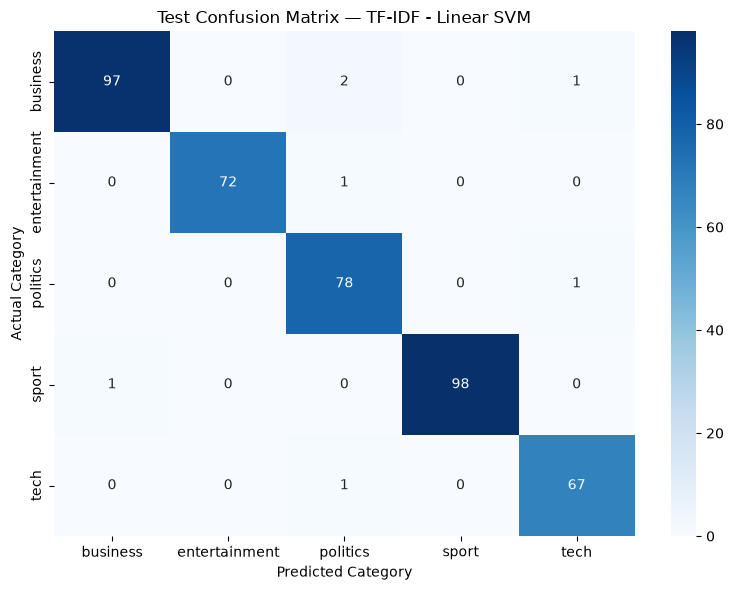

Saved: outputs/test_confusion_matrix.png


In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix
from pathlib import Path

best_model_name = test_results_df.iloc[0]["Model"]

if best_model_name in trained_models:
    best_model = trained_models[best_model_name]
    X_test_best = X_test_bow if "BoW" in best_model_name else X_test_tfidf
    final_predictions = best_model.predict(X_test_best)

elif best_model_name == "Word2Vec Neural Network":
    final_predictions = np.argmax(
        nn_model.predict(X_test_w2v, verbose=0), axis=1
    )

else:
    final_predictions = np.argmax(
        rnn_model.predict(X_test_pad, verbose=0), axis=1
    )

cm = confusion_matrix(y_test, final_predictions, labels=np.arange(num_classes))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title(f"Test Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.savefig("outputs/test_confusion_matrix.png", dpi=300)
plt.show()

print("Saved: outputs/test_confusion_matrix.png")

In [62]:
import joblib

saved_model = joblib.load("models/best_traditional_model.joblib")
saved_vectorizer = joblib.load("models/best_vectorizer.joblib")
saved_encoder = joblib.load("models/label_encoder.joblib")

sample_articles = [
    "The company reported higher profits and increased revenue.",
    "The actor will star in a new film released next month.",
    "Parliament debated the government's proposed legislation.",
    "The team won the football tournament final.",
    "Researchers developed a new artificial intelligence processor."
]

sample_features = saved_vectorizer.transform(sample_articles)
sample_predictions = saved_model.predict(sample_features)
sample_categories = saved_encoder.inverse_transform(sample_predictions)

for article, category in zip(sample_articles, sample_categories):
    print(f"{category.upper():15} | {article}")

BUSINESS        | The company reported higher profits and increased revenue.
ENTERTAINMENT   | The actor will star in a new film released next month.
POLITICS        | Parliament debated the government's proposed legislation.
SPORT           | The team won the football tournament final.
TECH            | Researchers developed a new artificial intelligence processor.


In [63]:
from pathlib import Path

required_files = [
    "models/best_traditional_model.joblib",
    "models/best_vectorizer.joblib",
    "models/label_encoder.joblib",
    "models/flipitnews_nn.keras",
    "models/flipitnews_rnn.keras",
    "models/word2vec.model",
    "models/rnn_tokenizer.joblib",
    "models/config.json",
    "outputs/model_comparison.csv",
    "outputs/test_set_results.csv",
    "outputs/model_performance_comparison.png",
    "outputs/confusion_matrix.png",
    "outputs/test_confusion_matrix.png"
]

for filename in required_files:
    file = Path(filename)
    status = "OK" if file.exists() and file.stat().st_size > 0 else "MISSING"
    print(f"{status:8} {filename}")

OK       models/best_traditional_model.joblib
OK       models/best_vectorizer.joblib
OK       models/label_encoder.joblib
OK       models/flipitnews_nn.keras
OK       models/flipitnews_rnn.keras
OK       models/word2vec.model
OK       models/rnn_tokenizer.joblib
OK       models/config.json
OK       outputs/model_comparison.csv
OK       outputs/test_set_results.csv
OK       outputs/model_performance_comparison.png
OK       outputs/confusion_matrix.png
OK       outputs/test_confusion_matrix.png


In [64]:
import pandas as pd
from IPython.display import display

test_results_df = pd.read_csv("outputs/test_set_results.csv")

display(test_results_df.round(4))

print("\nBest model by validation F1 score:", best_model_name)
print("Models evaluated:", len(test_results_df))
print("Test results file exists:", __import__("os").path.exists(
    "outputs/test_set_results.csv"
))

,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF - Linear SVM,0.9833,0.9837,0.9833,0.9834
1,TF-IDF - Logistic Regression,0.9737,0.9750,0.9737,0.9740
2,BoW - Logistic Regression,0.9714,0.9718,0.9714,0.9714
3,Word2Vec Neural Network,0.9690,0.9692,0.9690,0.9690
4,BoW - Naive Bayes,0.9666,0.9682,0.9666,0.9668
5,BiLSTM RNN,0.9475,0.9483,0.9475,0.9476



Best model by validation F1 score: TF-IDF - Linear SVM
Models evaluated: 6
Test results file exists: True


In [65]:
from pathlib import Path

print("Project directory:", Path.cwd())
print("\nRequired files:")

for f in [
    "models/best_traditional_model.joblib",
    "models/best_vectorizer.joblib",
    "models/label_encoder.joblib",
    "outputs/model_comparison.csv",
    "outputs/test_set_results.csv"
]:
    print(f, "OK" if Path(f).exists() else "MISSING")

Project directory: /home/aahana/24CD3002_AI_ML_Application_Assignments/Assignment-9

Required files:
models/best_traditional_model.joblib OK
models/best_vectorizer.joblib OK
models/label_encoder.joblib OK
outputs/model_comparison.csv OK
outputs/test_set_results.csv OK


In [66]:
%%writefile app.py
from pathlib import Path
import json
import joblib
import pandas as pd
import streamlit as st

BASE_DIR = Path(__file__).resolve().parent
MODEL_DIR = BASE_DIR / "models"
OUTPUT_DIR = BASE_DIR / "outputs"

st.set_page_config(
    page_title="FlipItNews | News Classifier",
    page_icon="📰",
    layout="wide"
)

@st.cache_resource
def load_artifacts():
    model = joblib.load(MODEL_DIR / "best_traditional_model.joblib")
    vectorizer = joblib.load(MODEL_DIR / "best_vectorizer.joblib")
    encoder = joblib.load(MODEL_DIR / "label_encoder.joblib")
    return model, vectorizer, encoder

model, vectorizer, encoder = load_artifacts()

st.title("📰 FlipItNews")
st.subheader("Intelligent News Category Classification")
st.write(
    "Enter a news article to classify it into one of five categories: "
    "business, entertainment, politics, sport, or tech."
)

with st.sidebar:
    st.header("About the project")
    st.write("**Algorithm:** Multinomial Naive Bayes")
    st.write("**Features:** Bag of Words (BoW)")
    st.write("**Categories:** 5")

    results_file = OUTPUT_DIR / "model_comparison.csv"
    if results_file.exists():
        results = pd.read_csv(results_file)
        st.write("**Validation model comparison**")
        st.dataframe(results, use_container_width=True, hide_index=True)

article = st.text_area(
    "Enter the news article",
    height=220,
    placeholder="Paste the news headline or article text here..."
)

if st.button("Classify News", type="primary", use_container_width=True):
    if not article.strip():
        st.warning("Please enter some news text first.")
    else:
        features = vectorizer.transform([article])
        prediction = model.predict(features)[0]
        category = encoder.inverse_transform([prediction])[0]

        st.success(f"Predicted category: {category.title()}")

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(features)[0]
            probability_df = pd.DataFrame({
                "Category": encoder.classes_,
                "Probability": probabilities
            }).sort_values("Probability", ascending=False)

            st.write("### Category confidence")
            st.bar_chart(
                probability_df.set_index("Category")["Probability"]
            )
            st.caption(
                "These are model probabilities, not guaranteed measures "
                "of correctness."
            )

st.divider()
st.caption("FlipItNews | NLP Text Classification Project")

Writing app.py


In [67]:
import pandas as pd

test_results_df = pd.read_csv("outputs/test_set_results.csv")
display(test_results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF - Linear SVM,0.983294,0.983663,0.983294,0.983368
1,TF-IDF - Logistic Regression,0.973747,0.975031,0.973747,0.973962
2,BoW - Logistic Regression,0.971360,0.971831,0.971360,0.971390
3,Word2Vec Neural Network,0.968974,0.969163,0.968974,0.969040
4,BoW - Naive Bayes,0.966587,0.968150,0.966587,0.966801
5,BiLSTM RNN,0.947494,0.948257,0.947494,0.947589
